## Set up Gurobipy
---

In Python, you can use `Gurobipy` as an optimization modeling library, which serves as an interface between the user and the solver. `Gurobipy` allows you to formulate and define optimization problems in a high-level, mathematical manner.

The solver, such as `Gurobi`, is responsible for solving the problem and providing an optimal solution.

Additionally, you can utilize `Matplotlib` to visualize the solution and `NumPy` for mathematical calculations.

The installation works with the following commands. `%` can be used to execute shell commands within a Jupyter Notebook code cell. Alternatively, you could execute `pip install gurobipy` and `pip install matplotlib` in your terminal/shell.

`pip` is the package manager for python.

In [146]:
# First you can check, whether the required packages are already installed
# (if not, you'll receive a warning)
%pip show gurobipy
%pip show matplotlib
%pip show numpy
%pip show pandas

Name: gurobipy
Version: 13.0.3
Summary: Python interface to Gurobi
Home-page: https://www.gurobi.com
Author: Gurobi Optimization, LLC
Author-email: 
License: Proprietary
Location: /Users/david.jansen/Documents/WS26TU/TU-Berlin-2026-Gurobi-and-Python-Seminar/.venv/lib/python3.13/site-packages
Requires: 
Required-by: 
Note: you may need to restart the kernel to use updated packages.
Name: matplotlib
Version: 3.11.2
Summary: Python plotting package
Home-page: https://matplotlib.org
Author: John D. Hunter, Michael Droettboom
Author-email: Unknown <matplotlib-users@python.org>
License: License agreement for matplotlib versions 1.3.0 and later

 1. This LICENSE AGREEMENT is between the Matplotlib Development Team
 ("MDT"), and the Individual or Organization ("Licensee") accessing and
 otherwise using matplotlib software in source or binary form and its
 associated documentation.

 2. Subject to the terms and conditions of this License Agreement, MDT
 hereby grants Licensee a nonexclusive, ro

In [147]:
#%pip install gurobipy
#%pip install matplotlib
#%pip install numpy
#%pip install pandas

Import them into this notebook

In [148]:
import gurobipy as gp 
from gurobipy import GRB
import matplotlib.pyplot as plt
import pandas as pd

---

# Master production planning

The goal is to determine the cost-optimal mix of flexibility instruments to fulfill a given dynamic demand.

## The basic model

### Objective function:

 0) The goal of the basic model is to minimize the total costs of holding, capacity level fixed costs and costs for additional workforce: 
 
$$ min \qquad z = \sum_{t=1}^{T} \sum_{j=1}^{J} k^h \times S_{tj} + \sum_{t=1}^{T} \sum_{i=1}^{I} k^{cl}_i \times Y_{ti} + \sum_{t=1}^{T}  k^{aw} \times W_{t}  $$
 


### Constraints:


1) Inventory balance: $ \hspace{56mm} S_{tj} = S_{(t-1)j} +X_{tj}-d_{tj}  \hspace{38mm} \forall t \in \{1,..,T\}, \forall j \in \{1,..,J\}$
 (Inventory(t,j) = Inventory(t-1,j)+Production(t,j)-demand(t,j))

2) Capacity restriction: $ \hspace{52mm} \sum_{j=1}^{J} X_{tj} \leq  \sum_{i=1}^{I} c_i \times Y_{ti}+ C_{t} + W_{t}  \hspace{18mm} \forall t \in \{1,..,T\} $
 (Number of production >= Capacity of used capcity + überstunden + mögliche leiharbeiter )

3) Labor time account balance:  $ \hspace{38mm} B_{t} =  B_{t-1} +\sum_{i=1}^{I} c_{i}\times Y_{ti}- c_{o}  +C_{t} \hspace{18mm} \forall t \in \{1,..,T\} $

4) Boundaries of labor time account: $ \hspace{30mm} lb^b \leq B_{t} \leq ub^b  \hspace{55mm} \forall t \in \{1,..,T\} $

5) Boundaries of capacity adjustment: $ \hspace{27mm}  lb^c \leq C_{t} \leq ub^c  \hspace{57mm} \forall t \in \{1,..,T\} $

6) Boundaries of additional workforce: $ \hspace{28mm} 0 \leq W_{t} \leq  ub^w  \hspace{56mm} \forall t \in \{1,..,T\} $

7) Initial value stock: $ \hspace{57mm} S_{0j}= iv^s_j \hspace{66mm}  \forall j \in \{1,..,J\}$

8) Initial value balance: $ \hspace{53mm}  B_{0} = iv^b   $

9) One configuration maximum: $\hspace{38mm} \sum_{i=1}^IY_{ti}\leq1 \hspace{62mm} \forall  t \in \{1,..,T\} $




---

#### Indices and sets
$j\in(1,..,J) \hspace{23mm}$   products                   

$t\in(1,..,T) \hspace{23mm}$   periods

$i= 1,...,I\hspace{25mm}$ production capacity level i 
   

#### Parameters
$k^h \hspace{41mm}$  Inventory costs per car and period [€ per product per period]

$k^{aw} \hspace{39mm}$ Costs for additional workforce [€ per product per period]

$k_i^{cl} \hspace{41mm}$ Fixed costs for production capacity level 𝑖 per period [€ per period]

$d_{tj} \hspace{41mm}$ Demand of product j in period t [product]

$c_0 \hspace{42mm}$ Regular production capacity per period [product equivalents]

$lb^c/ub^c \hspace{34mm}$ Maximal short-term capacity reduction / expansion per period [product equivalents]

$lb^b/ub^b \hspace{34mm}$ Lower / upper bound of labour time account [product equivalents]

$ub^w \hspace{39mm}$ Upper bound of additional workforce [product equivalents]

$iv^s_j \hspace{41mm}$ Initial stock of product j [product equivalents]

$iv_b \hspace{41mm}$ Initial balance of the labour time account [product equivalents]

$c_i \hspace{43mm}$ Capacity level i [product equivalents]


#### Decision variables

$X_{tj} \geq 0 \hspace{32mm}$ Number of units produced of product 𝑗 in period 𝑡

$S_{tj} \geq 0 \hspace{32mm}$ Number of units stored of product 𝑗 in period 𝑡

$C_t \hspace{42mm}$  Short-term capacity adjustment in period 𝑡 [product equivalents]

$B_t \hspace{42mm}$ Level of labor time account in period t [product equivalents] 

$Y_{ti} \in \{0,1\} \hspace{25mm}$ Selection of production capacity level i in period t

$W_{t} \geq 0 \hspace{33mm}$ Number of units produced by additional workforce [product equivalents] 

------------------------------------------------------------

### Create the model.
---

Initialize the model m with Gurobi as solver.

In [149]:
# Add Code
m = gp.Model("MILP")

### Sets and parameters
---

Insert the sets.

In [150]:
# Sets
Products = ["Macan", "Panamera", "Cayenne"]
Periods =  range(0, 12) # 12 Periods
CapLvls = ["Regular", "Basic", "Medium", "High"]

# Lengths
J = len(Products)
T = len(Periods)
I = len(CapLvls)

Insert the parameters.

In [151]:
#Parameters
k_h = 5                           #Inventory costs per car and period [€ per car/ period]
k_aw = 200                        #Costs for additional workers [€ per car/ period]   
c = [1000, 800, 1400, 1600]       #Capacity per period [cars] per capacity level
k_kp = [0, 1000, 2000, 3000]      #Fixed costs for production capacity level 𝑖 per period [€ / period]

lb_c = -100                       #Maximal short-term capacity reduction per period
ub_c = 100                        #Maximal short-term capacity expansion per period
iv_s = [0,0,0]                    #initial stock of product j
ub_w = 400                        #Maximal additional workforce per period

#Parameters for labor account
lb_b = -600                       #Lower boundary of labor time account [car equivalents]
ub_b = 600                        #upper boundary of labor time account [car equivalents]
iv_b = 0                          #Initial balance of the labor time account [car equivalents]

Demand data is provided in a separate CSV.file

In [152]:
# Demand of product 𝑗 in period 𝑡
demand_df = pd.read_csv("MPPDemand_engl.csv")
demand_df

,Macan,Panamera,Cayenne
0,200,200,100
1,300,200,500
2,600,200,600
3,600,100,600
4,700,200,700
5,800,200,800
6,500,200,500
7,700,200,500
8,300,200,400
9,100,100,400


Transfer Dataframe to Matrix conversion

In [153]:
# Convert to NumPy 2D Array (Matrix)
d = demand_df.to_numpy()
print(d.shape)
# ADD CODE

(12, 3)


### Decision variables
---

Number of units produced of product j in period t

In [154]:
# ADD CODE
X = m.addVars(T,J,vtype=GRB.INTEGER, lb = 0, name ="X")

Number of units stored of product j in period t

In [155]:
# ADD CODE
S = m.addVars(T,J,vtype=GRB.INTEGER, lb = 0, name = "S")

Short-term capacity adjustment in period 𝑡 [car equivalents]

In [156]:
# ADD CODE
C = m.addVars(T,vtype=GRB.INTEGER,lb=lb_c, ub=ub_c, name = "C")

Level of labor time account in period 𝑡 [car equivalents]

In [157]:
B = m.addVars(range(-1, T), vtype=GRB.INTEGER, lb=lb_b, ub=ub_b, name="B")

Selection of production capacity level

In [158]:
# ADD CODE
Y = m.addVars(T,I, vtype=GRB.BINARY, name="Y")

Number of units produced by additional workers

In [159]:
# ADD CODE
W = m.addVars(T, vtype=GRB.INTEGER, lb=0,ub=ub_w, name="W")

### Objective function 
---

Define the objective value to minimize the total costs.

$$ min \qquad z = \sum_{t=1}^{T} \sum_{j=1}^{J} k^h \times S_{tj} + \sum_{t=1}^{T} \sum_{i=1}^{I} k^{kp}_i \times Y_{ti} + \sum_{t=1}^{T}  k^{aw} \times W_{t}  $$

In [160]:
# ADD CODE
inventory_cost = gp.quicksum(
    k_h*S[t,j]
    for j in range(J)
    for t in range(T)
)
fixed_cost = gp.quicksum(
    k_kp[i]*Y[t,i]
    for t in range(T)
    for i in range(I)
)
additional_cost = gp.quicksum(
    k_aw*W[t]
    for t in range(T)
)
m.setObjective(inventory_cost+fixed_cost+additional_cost, GRB.MINIMIZE)

### Constraints
---

**1) Inventory balance** 

$$ S_{tj} = S_{t-1j} + X_{tj} - d_{tj}  \qquad \forall t \in \{1,..,T\} j \in \{1,..,J\}  $$

In [161]:
# ADD CODE
m.addConstrs((S[0, j] == iv_s[j] + X[0, j] - d[0, j] for j in range(J)), name="Inventory_Balance_t0")
m.addConstrs((S[t, j] == S[t-1, j] + X[t, j] - d[t, j] for t in range(1, T) for j in range(J)), name="Inventory_Balance")

{(1, 0): <gurobi.Constr *Awaiting Model Update*>,
 (1, 1): <gurobi.Constr *Awaiting Model Update*>,
 (1, 2): <gurobi.Constr *Awaiting Model Update*>,
 (2, 0): <gurobi.Constr *Awaiting Model Update*>,
 (2, 1): <gurobi.Constr *Awaiting Model Update*>,
 (2, 2): <gurobi.Constr *Awaiting Model Update*>,
 (3, 0): <gurobi.Constr *Awaiting Model Update*>,
 (3, 1): <gurobi.Constr *Awaiting Model Update*>,
 (3, 2): <gurobi.Constr *Awaiting Model Update*>,
 (4, 0): <gurobi.Constr *Awaiting Model Update*>,
 (4, 1): <gurobi.Constr *Awaiting Model Update*>,
 (4, 2): <gurobi.Constr *Awaiting Model Update*>,
 (5, 0): <gurobi.Constr *Awaiting Model Update*>,
 (5, 1): <gurobi.Constr *Awaiting Model Update*>,
 (5, 2): <gurobi.Constr *Awaiting Model Update*>,
 (6, 0): <gurobi.Constr *Awaiting Model Update*>,
 (6, 1): <gurobi.Constr *Awaiting Model Update*>,
 (6, 2): <gurobi.Constr *Awaiting Model Update*>,
 (7, 0): <gurobi.Constr *Awaiting Model Update*>,
 (7, 1): <gurobi.Constr *Awaiting Model Update*>,


**2) Capacity restriction**

$$ \sum_{j=1}^{J} X_{tj} \leq \sum_{i=1}^{I} c_{i}\times Y_{ti}+ C_{t} + W_t \qquad \forall t \in \{1,..,T\} \$$

In [162]:
# ADD CODE
m.addConstrs(
    (sum(X[t, j] for j in range(J)) <= sum(c[i] * Y[t, i] for i in range(I)) + C[t] + W[t]
     for t in range(T)),
    name="capacity_restriction"
)

{0: <gurobi.Constr *Awaiting Model Update*>,
 1: <gurobi.Constr *Awaiting Model Update*>,
 2: <gurobi.Constr *Awaiting Model Update*>,
 3: <gurobi.Constr *Awaiting Model Update*>,
 4: <gurobi.Constr *Awaiting Model Update*>,
 5: <gurobi.Constr *Awaiting Model Update*>,
 6: <gurobi.Constr *Awaiting Model Update*>,
 7: <gurobi.Constr *Awaiting Model Update*>,
 8: <gurobi.Constr *Awaiting Model Update*>,
 9: <gurobi.Constr *Awaiting Model Update*>,
 10: <gurobi.Constr *Awaiting Model Update*>,
 11: <gurobi.Constr *Awaiting Model Update*>}

**3) Labor time account balance**

$$ B_{t} =  B_{t-1} +\sum_{i=1}^{I} c_{i}\times Y_{ti}- c_{o}  +C_{t} \qquad \forall t \in \{1,..,T\} $$

In [163]:
# ADD CODE
# Initialisierung für Periode -1
m.addConstr(B[-1] == iv_b, name="initial_value_labour_time")

# Bilanz für alle Perioden t von 0 bis T-1
m.addConstrs(
    (B[t] == B[t-1] + sum(c[i] * Y[t, i] for i in range(I)) - c[0] + C[t]
     for t in range(T)),
    name="Labor_Balance"
)

{0: <gurobi.Constr *Awaiting Model Update*>,
 1: <gurobi.Constr *Awaiting Model Update*>,
 2: <gurobi.Constr *Awaiting Model Update*>,
 3: <gurobi.Constr *Awaiting Model Update*>,
 4: <gurobi.Constr *Awaiting Model Update*>,
 5: <gurobi.Constr *Awaiting Model Update*>,
 6: <gurobi.Constr *Awaiting Model Update*>,
 7: <gurobi.Constr *Awaiting Model Update*>,
 8: <gurobi.Constr *Awaiting Model Update*>,
 9: <gurobi.Constr *Awaiting Model Update*>,
 10: <gurobi.Constr *Awaiting Model Update*>,
 11: <gurobi.Constr *Awaiting Model Update*>}

**4) Boundaries of labor time account**

$$ lb^b \leq B_{t} \leq ub^b \qquad \forall t \in \{1,..,T\} $$

In [164]:
""""
#Why don't we need this constraint?
labTimeMin = m.addConstrs((B[t] >= lb_b for t in range(T)), name="labTimeMin") 
labTimeMax = m.addConstrs((B[t] <= ub_b for t in range(T)), name="labTimeMax")
"""
#because we set lower / upperboudns for these variables

'"\n#Why don\'t we need this constraint?\nlabTimeMin = m.addConstrs((B[t] >= lb_b for t in range(T)), name="labTimeMin") \nlabTimeMax = m.addConstrs((B[t] <= ub_b for t in range(T)), name="labTimeMax")\n'

**5) Boundaries of capacity adjustment**

$$  lb^c \leq C_{t} \leq ub^c \qquad \forall t \in \{1,..,T\} $$

In [165]:
# ADD CODE
m.addConstrs((lb_c <= C[t] for t in range(T)), name="lowerbound_capacity")
m.addConstrs((ub_c >= C[t] for t in range(T)), name="upperbound_capacity")

{0: <gurobi.Constr *Awaiting Model Update*>,
 1: <gurobi.Constr *Awaiting Model Update*>,
 2: <gurobi.Constr *Awaiting Model Update*>,
 3: <gurobi.Constr *Awaiting Model Update*>,
 4: <gurobi.Constr *Awaiting Model Update*>,
 5: <gurobi.Constr *Awaiting Model Update*>,
 6: <gurobi.Constr *Awaiting Model Update*>,
 7: <gurobi.Constr *Awaiting Model Update*>,
 8: <gurobi.Constr *Awaiting Model Update*>,
 9: <gurobi.Constr *Awaiting Model Update*>,
 10: <gurobi.Constr *Awaiting Model Update*>,
 11: <gurobi.Constr *Awaiting Model Update*>}

**6) Boundaries for additional workforce**

$$  0 \leq W_{t} \leq ub^w \qquad \forall t \in \{1,..,T\} $$

In [166]:
# ADD CODE
m.addConstrs((0 <= W[t] for t in range(T)), name="Workforce_lowerbound")
m.addConstrs((ub_w >= W[t] for t in range(T)), name="Workforce_upperbound")

{0: <gurobi.Constr *Awaiting Model Update*>,
 1: <gurobi.Constr *Awaiting Model Update*>,
 2: <gurobi.Constr *Awaiting Model Update*>,
 3: <gurobi.Constr *Awaiting Model Update*>,
 4: <gurobi.Constr *Awaiting Model Update*>,
 5: <gurobi.Constr *Awaiting Model Update*>,
 6: <gurobi.Constr *Awaiting Model Update*>,
 7: <gurobi.Constr *Awaiting Model Update*>,
 8: <gurobi.Constr *Awaiting Model Update*>,
 9: <gurobi.Constr *Awaiting Model Update*>,
 10: <gurobi.Constr *Awaiting Model Update*>,
 11: <gurobi.Constr *Awaiting Model Update*>}

**7) Initial value stock**

$$ S_{0j} = iv^s_{j} \qquad \forall j \in \{1,..,J\} $$

In [167]:
# ADD CODE
m.addConstrs(((S[0,j] == iv_s[j]) for j in range(J)), name="initial_value_stock")

{0: <gurobi.Constr *Awaiting Model Update*>,
 1: <gurobi.Constr *Awaiting Model Update*>,
 2: <gurobi.Constr *Awaiting Model Update*>}

**8) Initial value labour time**

$$ B_0 = iv^b $$

In [168]:
# ADD CODE
m.addConstr(B[0] == iv_b, name = "initial_value_labour_time")

<gurobi.Constr *Awaiting Model Update*>

**9) One configuration max**

$$ \sum_{i=1}^{I} Y_{ti} \leq 1  \qquad \forall t \in \{1,..,T\} $$

In [169]:
# ADD CODE
m.addConstrs((1 >= sum(Y[t,i] for i in range(I)) for t in range(T)), name = "One_config_max")

{0: <gurobi.Constr *Awaiting Model Update*>,
 1: <gurobi.Constr *Awaiting Model Update*>,
 2: <gurobi.Constr *Awaiting Model Update*>,
 3: <gurobi.Constr *Awaiting Model Update*>,
 4: <gurobi.Constr *Awaiting Model Update*>,
 5: <gurobi.Constr *Awaiting Model Update*>,
 6: <gurobi.Constr *Awaiting Model Update*>,
 7: <gurobi.Constr *Awaiting Model Update*>,
 8: <gurobi.Constr *Awaiting Model Update*>,
 9: <gurobi.Constr *Awaiting Model Update*>,
 10: <gurobi.Constr *Awaiting Model Update*>,
 11: <gurobi.Constr *Awaiting Model Update*>}

### Solve and display results
---

Get the whole model m displayed.

In [170]:
# ADD CODE
m.update()
m.printStats()

Statistics for model 'MILP':
  Problem type                : MIP
  Linear constraint matrix    : 125 rows, 157 columns, 398 nonzeros
  Variable types              : 0 continuous, 157 integer (48 binary)
  Matrix range                : [1e+00, 2e+03]
  Objective range             : [5e+00, 3e+03]
  Bounds range                : [1e+00, 6e+02]
  RHS range                   : [1e+00, 1e+03]


Run the model m.

In [171]:
# ADD CODE
m.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 25.0.0 25A362)

CPU model: Apple M1
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 125 rows, 157 columns and 398 nonzeros (Min)
Model fingerprint: 0x229e9f6a
Model has 84 linear objective coefficients
Variable types: 0 continuous, 157 integer (48 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+03]
  Objective range  [5e+00, 3e+03]
  Bounds range     [1e+00, 6e+02]
  RHS range        [1e+00, 1e+03]

Presolve removed 65 rows and 24 columns
Presolve time: 0.01s
Presolved: 60 rows, 133 columns, 297 nonzeros
Variable types: 0 continuous, 133 integer (43 binary)

Root relaxation: objective 4.220000e+05, 41 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0 422000.000    0    8          - 422000.000      

### Get the results displayed.

Take a look at the objective value.

In [172]:
print("Objective value: ", m.objVal, " found after ", m.Runtime, " seconds. Relative gap is: ", m.MIPGap)

Objective value:  422500.0  found after  0.023872852325439453  seconds. Relative gap is:  0.0


#### Get displayed:

- The number of units produced of product j in period t
- The number of units stored of product j in period t
- The level of labor time account in period 𝑡 [car equivalents]

In [175]:

# 1. Produktion als Tabelle (Perioden x Produkte)
prod_data = [[X[t, j].X for j in range(J)] for t in range(T)]
df_prod = pd.DataFrame(prod_data, columns=Products)
print("--- Produktion (X) ---")
display(df_prod)

# 2. Lagerbestand als Tabelle (Perioden x Produkte)
stock_data = [[S[t, j].X for j in range(J)] for t in range(T)]
df_stock = pd.DataFrame(stock_data, columns=Products)
print("\n--- Lagerbestand (S) ---")
display(df_stock)

# 3. Arbeitszeitkonto als Tabelle
df_labor = pd.DataFrame([B[t].X for t in range(T)], columns=["Labor Account (B)"])
print("\n--- Arbeitszeitkonto (B) ---")
display(df_labor)

--- Produktion (X) ---


,Macan,Panamera,Cayenne
0,200.0,200.0,100.0
1,300.0,200.0,500.0
2,600.0,200.0,600.0
3,700.0,100.0,600.0
4,600.0,200.0,700.0
5,800.0,200.0,800.0
6,500.0,200.0,500.0
7,700.0,200.0,500.0
8,300.0,200.0,400.0
9,100.0,100.0,400.0



--- Lagerbestand (S) ---


,Macan,Panamera,Cayenne
0,-0.0,-0.0,-0.0
1,0.0,0.0,0.0
2,-0.0,-0.0,-0.0
3,100.0,-0.0,-0.0
4,-0.0,-0.0,-0.0
5,-0.0,-0.0,-0.0
6,-0.0,-0.0,-0.0
7,-0.0,-0.0,-0.0
8,-0.0,-0.0,-0.0
9,-0.0,-0.0,-0.0



--- Arbeitszeitkonto (B) ---


,Labor Account (B)
0,-0.0
1,-100.0
2,0.0
3,100.0
4,200.0
5,600.0
6,500.0
7,600.0
8,500.0
9,400.0


**Illustrate your results**

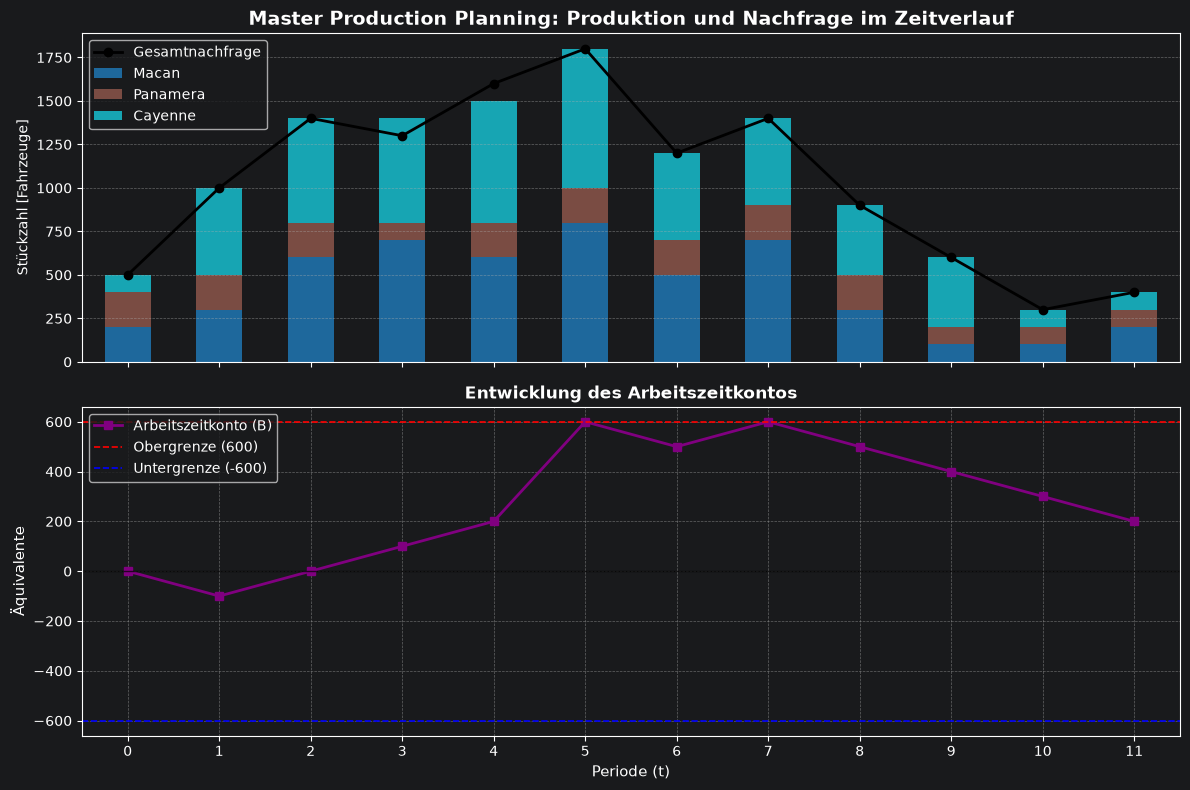

In [177]:

# Erstelle eine Figure mit 2 Subplots untereinander
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# 1. Subplot: Produktion (gestapelt) vs. Gesamtnachfrage
# Berechne die Gesamtnachfrage pro Periode aus dem DataFrame 'd'
total_demand = [sum(d[t]) for t in range(T)]

df_prod.plot(kind='bar', stacked=True, ax=ax1, colormap='tab10', alpha=0.85)
ax1.plot(range(T), total_demand, color='black', marker='o', linewidth=2, label='Gesamtnachfrage')

ax1.set_title("Master Production Planning: Produktion und Nachfrage im Zeitverlauf", fontsize=14, fontweight='bold')
ax1.set_ylabel("Stückzahl [Fahrzeuge]")
ax1.legend(loc="upper left")
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# 2. Subplot: Arbeitszeitkonto (B) mit Grenzen
ax2.plot(range(T), [B[t].X for t in range(T)], color='purple', marker='s', linewidth=2, label='Arbeitszeitkonto (B)')
ax2.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.7)
ax2.axhline(ub_b, color='red', linestyle='--', linewidth=1.2, label=f'Obergrenze ({ub_b})')
ax2.axhline(lb_b, color='blue', linestyle='--', linewidth=1.2, label=f'Untergrenze ({lb_b})')

ax2.set_title("Entwicklung des Arbeitszeitkontos", fontsize=12, fontweight='bold')
ax2.set_xlabel("Periode (t)", fontsize=11)
ax2.set_ylabel("Äquivalente", fontsize=11)
ax2.set_xticks(range(T))
ax2.legend(loc="upper left")
ax2.grid(True, linestyle='--', alpha=0.5)

# Layout anpassen und anzeigen
plt.tight_layout()
plt.show()